# Estimating Asset Correlation from Forty Years of U.S. Bank Charge-Offs: Vasicek Maximum Likelihood versus the Basel Correlation Formula, the Procyclicality of Capital, and Machine-Learning Macro Default Models

The Basel IRB formula turns a probability of default into capital with one more number: the **asset correlation** R, the share of a borrower's risk that comes from a common factor, the economy. Basel fixes R by asset class (12–24% for corporates, 15% for mortgages, 4% for credit cards), calibrated in 2004 on limited data. If borrowers' defaults move together more than R assumes, capital covers less than the one-in-a-thousand-year loss it is meant to. This notebook estimates R from the default rates of U.S. banks' loan books since 1985, compares it with the Basel values, checks whether Basel capital would have covered the worst year observed, and asks how much of the common factor the macro economy explains with linear and machine-learning default models.

**What it does.**

1. It reads quarterly charge-off rates of all U.S. commercial banks by loan type (business, commercial real estate, single-family mortgages, credit cards, other consumer, farmland, leases, and all loans) since 1985 or 1991, and turns them into annual default rates with a loss-given-default assumption for each type.
2. It estimates the asset correlation of the Vasicek one-factor model three ways: the method of moments on probit-transformed default rates, maximum likelihood with a persistent (AR(1)) systematic factor, and a block bootstrap for confidence intervals.
3. It compares the estimates with Basel's R at the same long-run PD, computes the 99.9% default rate each implies, and the return period of the worst year actually observed.
4. It shows how capital would have moved over the cycle with point-in-time PDs.
5. It forecasts next year's default rate from macro variables (unemployment, growth, house prices, credit spreads, interest rates) with a linear factor model, LightGBM and a neural network, out of time from 2000, and measures how much systematic variance remains after the macro economy is accounted for: the correlation a point-in-time model should carry.

**Data.** Charge-off rates on loans and leases at all commercial banks by type (Federal Reserve, via FRED); unemployment, real GDP, house prices, the Baa–Treasury spread and the federal funds rate (FRED).

**Methods.** The Vasicek one-factor (asymptotic single-risk-factor) model, method-of-moments and maximum-likelihood estimation with an AR(1) latent factor, block bootstrap, the Basel IRB correlation functions, 99.9% conditional default rates, linear probit factor regression, LightGBM, a multilayer perceptron, and rolling-origin out-of-time tests.

**Key output.** Estimated asset correlations with confidence intervals by loan type against Basel's values; implied and observed worst-year default rates; capital through the cycle; and the out-of-time accuracy and residual correlation of the macro default models.

## 1. The one-factor model behind Basel

In the Vasicek model, borrower *i* defaults when its asset value falls below a threshold. Asset values are driven by a common factor *Z* and an idiosyncratic shock:

*Aᵢ* = √R *Z* + √(1 − R) εᵢ,  default if *Aᵢ* < Φ⁻¹(PD).

In a large portfolio, the default rate in a year with factor *Z* = *z* is

DR(*z*) = Φ( (Φ⁻¹(PD) − √R *z*) / √(1 − R) ).

It follows that Φ⁻¹(DR) is normally distributed with mean Φ⁻¹(PD)/√(1 − R) and variance R/(1 − R). So the **variance of the probit of the default rate over time identifies R**: R = σ²/(1 + σ²). Basel sets capital at the default rate in the 1-in-1,000 bad year (*z* = Φ⁻¹(0.001)), minus expected loss, times LGD.

**Persistence.** Default rates are serially correlated: a bad year is followed by another. Treating annual observations as independent understates the uncertainty of σ², and with only forty years of data the uncertainty is large. A model with an autoregressive factor estimates the same unconditional variance while accounting for persistence.

**Point-in-time models.** If a bank's PDs move with the macro economy, part of the common factor is already in the PD, and the correlation that remains is smaller. That residual correlation, not the full one, is what a point-in-time model should use; applying Basel's through-the-cycle R to point-in-time PDs double-counts the cycle.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from scipy.optimize import minimize
from scipy.stats import norm
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 1985
rng = np.random.default_rng(SEED)
SERIES = {  # FRED id: (label, assumed LGD, Basel IRB class)
    "CORBLACBS": ("business loans", 0.45, "corporate"),
    "CORCREXFACBS": ("commercial real estate", 0.35, "corporate"),
    "CORSFRMACBS": ("single-family mortgages", 0.25, "residential"),
    "CORCCACBS": ("credit cards", 0.85, "QRRE"),
    "COROCLACBS": ("other consumer", 0.60, "other retail"),
    "CORFLACBS": ("farmland", 0.35, "corporate"),
    "CORLFRACBS": ("leases", 0.45, "corporate"),
    "CORALACBN": ("all loans", 0.45, "corporate"),
}
DELINQ = {
    "DRBLACBS": "business loans",
    "DRCRELEXFACBS": "commercial real estate",
    "DRSFRMACBS": "single-family mortgages",
    "DRCCLACBS": "credit cards",
    "DRALACBN": "all loans",
}
MACRO = {
    "UNRATE": "unemployment",
    "GDPC1": "real GDP",
    "USSTHPI": "house prices",
    "BAA10Y": "Baa spread",
    "FEDFUNDS": "fed funds",
}
N_BOOT, BLOCK, TEST_FROM = 2000, 4, 2000

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. From charge-off rates to default rates

The Federal Reserve publishes the annualised net charge-off rate of all commercial banks by loan type each quarter. A charge-off is a default times its loss severity, so the default rate is approximated as the charge-off rate divided by an LGD for each type: 45% for business loans and leases, 35% for commercial real estate and farmland, 25% for mortgages, 85% for credit cards and 60% for other consumer loans. The annual default rate is the average of the four quarters. Section 5 shows how much the LGD assumption changes the estimates.

In [3]:
def fetch_fred():
    return pd.DataFrame({
        k: fred.get_series(k)
        for k in list(SERIES) + list(DELINQ) + list(MACRO)
    })


RAW = cached(
    "fred_chargeoffs_delinquency_macro", fetch_fred, max_age_hours=24 * 7
)
RAW.index = pd.to_datetime(RAW.index)
CO = RAW[list(SERIES)].resample("QE").mean() / 100
CO.columns = [SERIES[c][0] for c in CO.columns]
LGD = {v[0]: v[1] for v in SERIES.values()}
CLS = {v[0]: v[2] for v in SERIES.values()}
# quarterly annualised default rate, floored at 1bp
DRQ = (CO / pd.Series(LGD)).clip(1e-4, 0.999)
# complete years only
DRA = DRQ.resample("YE").mean().where(DRQ.resample("YE").count() == 4)
DRA.index = DRA.index.year
DRA = DRA.dropna(how="all")
SUMMARY = pd.DataFrame({
    "first year": DRA.apply(lambda s: s.first_valid_index()),
    "years": DRA.count(),
    "mean default rate": DRA.mean(),
    "worst year": DRA.idxmax(),
    "worst default rate": DRA.max(),
    "best default rate": DRA.min(),
})
SUMMARY.style.format({
    "first year": "{:.0f}",
    "years": "{:.0f}",
    "worst year": "{:.0f}",
    "mean default rate": "{:.2%}",
    "worst default rate": "{:.2%}",
    "best default rate": "{:.2%}",
})

,first year,years,mean default rate,worst year,worst default rate,best default rate
business loans,1985,41,1.68%,2009,5.12%,0.36%
commercial real estate,1991,35,1.33%,2010,6.71%,0.04%
single-family mortgages,1991,35,1.43%,2009,9.33%,0.01%
credit cards,1985,41,5.01%,2009,11.10%,2.41%
other consumer,1985,41,1.78%,2009,5.10%,0.62%
farmland,1991,35,0.28%,2010,1.22%,0.03%
leases,1985,41,0.92%,2009,2.89%,0.18%
all loans,1985,41,1.91%,2010,5.91%,0.54%


## 4. Estimating the asset correlation

**Method of moments.** With *y*ₜ = Φ⁻¹(DRₜ), σ² = Var(*y*) and R = σ²/(1 + σ²). The long-run PD is Φ(mean(*y*) × √(1 − R)).

**Maximum likelihood with a persistent factor.** *y*ₜ = μ + σ *x*ₜ with *x*ₜ = φ *x*ₜ₋₁ + √(1 − φ²) *e*ₜ: a Gaussian AR(1) process with unconditional variance σ². The exact likelihood is maximised over μ, σ and φ.

**Block bootstrap.** Years are resampled in blocks of four, keeping the persistence of the cycle, and R is re-estimated 2,000 times for a 90% interval.

**Basel's R** is evaluated at the estimated long-run PD with the formula of each class.

In [4]:
def basel_r(pd_, cls):
    if cls == "residential":
        return 0.15
    if cls == "QRRE":
        return 0.04
    if cls == "other retail":
        e = (1 - np.exp(-35 * pd_)) / (1 - np.exp(-35))
        return 0.03 * e + 0.16 * (1 - e)
    e = (1 - np.exp(-50 * pd_)) / (1 - np.exp(-50))
    return 0.12 * e + 0.24 * (1 - e)


def mom(y):
    s2 = np.var(y, ddof=1)
    r = s2 / (1 + s2)
    return r, norm.cdf(np.mean(y) * np.sqrt(1 - r))


def ar1_mle(y):
    y = np.asarray(y)

    def nll(p):
        mu, ls, a = p
        s, phi = np.exp(ls), np.tanh(a)
        e0 = (y[0] - mu) / s
        ll = norm.logpdf(e0) - np.log(s)
        innov = (y[1:] - mu - phi * (y[:-1] - mu)) / (s * np.sqrt(1 - phi**2))
        ll += (norm.logpdf(innov) - np.log(s * np.sqrt(1 - phi**2))).sum()
        return -ll

    res = minimize(
        nll,
        [y.mean(), np.log(y.std()), 0.5],
        method="Nelder-Mead",
        options={"maxiter": 5000, "xatol": 1e-8, "fatol": 1e-10},
    )
    mu, s, phi = res.x[0], np.exp(res.x[1]), np.tanh(res.x[2])
    r = s**2 / (1 + s**2)
    return r, norm.cdf(mu * np.sqrt(1 - r)), phi


def block_boot(y, n=N_BOOT, block=BLOCK):
    y = np.asarray(y)
    out = np.empty(n)
    for b in range(n):
        starts = rng.integers(
            0, len(y) - block + 1, size=int(np.ceil(len(y) / block))
        )
        yb = np.concatenate([y[s : s + block] for s in starts])[: len(y)]
        out[b] = mom(yb)[0]
    return np.percentile(out, [5, 95])


rows = {}
for c in DRA.columns:
    y = norm.ppf(DRA[c].dropna())
    r_m, pd_m = mom(y)
    r_l, pd_l, phi = ar1_mle(y)
    lo, hi = block_boot(y)
    rows[c] = {
        "long-run PD": pd_l,
        "R, moments": r_m,
        "R, AR(1) MLE": r_l,
        "R 90% interval low": lo,
        "R 90% interval high": hi,
        "factor persistence φ": phi,
        "Basel R": basel_r(pd_l, CLS[c]),
        "Basel class": CLS[c],
    }
CORR = pd.DataFrame(rows).T
CORR["estimate / Basel"] = CORR["R, AR(1) MLE"].astype(float) / CORR[
    "Basel R"
].astype(float)
CORR.style.format(
    {
        c: "{:.1%}"
        for c in [
            "long-run PD",
            "R, moments",
            "R, AR(1) MLE",
            "R 90% interval low",
            "R 90% interval high",
            "Basel R",
        ]
    }
    | {"factor persistence φ": "{:.2f}", "estimate / Basel": "{:.2f}"}
)

,long-run PD,"R, moments","R, AR(1) MLE",R 90% interval low,R 90% interval high,factor persistence φ,Basel R,Basel class,estimate / Basel
business loans,1.8%,8.1%,7.7%,5.9%,9.3%,0.79,17.0%,corporate,0.46
commercial real estate,1.8%,24.7%,25.5%,11.6%,29.8%,0.89,17.0%,corporate,1.51
single-family mortgages,1.0%,32.3%,33.2%,14.8%,41.0%,0.95,15.0%,residential,2.22
credit cards,4.9%,2.5%,2.4%,1.2%,3.7%,0.75,4.0%,QRRE,0.61
other consumer,1.7%,2.6%,2.5%,1.1%,4.1%,0.80,10.1%,other retail,0.25
farmland,0.3%,8.6%,8.9%,3.4%,11.6%,0.75,22.4%,corporate,0.40
leases,0.9%,6.3%,6.1%,4.6%,7.5%,0.64,19.5%,corporate,0.31
all loans,1.9%,4.8%,4.3%,2.4%,7.1%,0.81,16.7%,corporate,0.26


## 5. Would Basel capital have covered the worst year?

At the long-run PD, the Vasicek model gives the default rate of the 1-in-1,000 year for any R. If R is too low, the 99.9% default rate is too low, and the worst year observed may exceed it. The table compares the 99.9% default rate under Basel's R and under the estimated R with the worst annual default rate in the data, and gives the return period of that worst year under each R.

The LGD assumption changes the level of default rates; the second table re-estimates R with LGDs 15 points lower and higher, and with a proxy that needs no LGD: the delinquency rate (loans 30 days or more past due) of the same books, available for five of them. Default rates are floored at one basis point a year, because mortgage charge-offs were zero or negative in some recent years even though borrowers did default.

In [5]:
def dr_q(pd_, r, q=0.999):
    return norm.cdf(
        (norm.ppf(pd_) + np.sqrt(r) * norm.ppf(q)) / np.sqrt(1 - r)
    )


def return_period(dr, pd_, r):
    # factor value that produces dr
    z = (norm.ppf(pd_) - np.sqrt(1 - r) * norm.ppf(dr)) / np.sqrt(r)
    return 1 / norm.cdf(z)


cover = {}
for c, row in CORR.iterrows():
    pd_, rb, re_ = (
        float(row["long-run PD"]),
        float(row["Basel R"]),
        float(row["R, AR(1) MLE"]),
    )
    worst = DRA[c].max()
    cover[c] = {
        "worst default rate": worst,
        "worst year": int(DRA[c].idxmax()),
        "99.9% DR, Basel R": dr_q(pd_, rb),
        "99.9% DR, estimated R": dr_q(pd_, re_),
        "return period of worst year, Basel R (years)": return_period(
            worst, pd_, rb
        ),
        "return period, estimated R (years)": return_period(worst, pd_, re_),
    }
COVER = pd.DataFrame(cover).T
display(
    COVER.style.format({
        "worst default rate": "{:.2%}",
        "worst year": "{:.0f}",
        "99.9% DR, Basel R": "{:.2%}",
        "99.9% DR, estimated R": "{:.2%}",
        "return period of worst year, Basel R (years)": "{:,.0f}",
        "return period, estimated R (years)": "{:,.0f}",
    })
)
sens = {}
for c in DRA.columns:
    for d in (-0.15, 0.15):
        lgd = min(max(LGD[c] + d, 0.1), 0.95)
        dr = (CO[c].resample("YE").mean().dropna() / lgd).clip(1e-4, 0.999)
        sens[(c, "LGD 15 pts lower" if d < 0 else "LGD 15 pts higher")] = (
            ar1_mle(norm.ppf(dr))[0]
        )
SENS = pd.Series(sens).unstack()[["LGD 15 pts lower", "LGD 15 pts higher"]]
SENS.insert(1, "base LGD", CORR["R, AR(1) MLE"].astype(float))
# a second proxy that does not depend on LGD: the delinquency rate (30+ days
# past due) on the same books
DLQ = (RAW[list(DELINQ)].resample("QE").mean() / 100).rename(columns=DELINQ)
DLQ = DLQ.resample("YE").mean().where(DLQ.resample("YE").count() == 4)
DLQ.index = DLQ.index.year
SENS["R from delinquency rates"] = pd.Series({
    c: ar1_mle(norm.ppf(DLQ[c].dropna().clip(1e-4, 0.999)))[0]
    for c in DLQ.columns
})
SENS.style.format("{:.1%}")

,worst default rate,worst year,"99.9% DR, Basel R","99.9% DR, estimated R","return period of worst year, Basel R (years)","return period, estimated R (years)"
business loans,5.12%,2009,18.03%,9.72%,15,37
commercial real estate,6.71%,2010,18.07%,26.46%,28,19
single-family mortgages,9.33%,2009,10.79%,24.79%,525,69
credit cards,11.10%,2009,14.42%,11.67%,96,544
other consumer,5.10%,2009,11.66%,5.01%,26,"1,210"
farmland,1.22%,2010,6.87%,2.63%,21,55
leases,2.89%,2009,13.64%,5.09%,14,52
all loans,5.91%,2010,18.54%,7.09%,18,247


,LGD 15 pts lower,base LGD,LGD 15 pts higher,R from delinquency rates
all loans,4.9%,4.3%,3.9%,5.3%
business loans,8.5%,7.7%,7.0%,7.9%
commercial real estate,30.6%,25.5%,25.4%,16.5%
credit cards,2.6%,2.4%,2.3%,2.2%
farmland,11.1%,8.9%,9.5%,nan%
leases,6.6%,6.1%,5.6%,nan%
other consumer,2.7%,2.5%,2.3%,nan%
single-family mortgages,45.1%,33.2%,29.0%,6.2%


## 6. Capital through the cycle

The IRB capital requirement per unit of exposure, *K* = LGD × [DR₉₉.₉ − PD], is computed each year with two PDs: the long-run average (through the cycle) and the previous year's default rate (point in time), both with Basel's R. A point-in-time bank would have held the least capital just before the crisis and the most after it.

In [6]:
def k_cap(pd_, r, lgd):
    pd_ = np.clip(pd_, 0.0003, 0.999)
    return lgd * (dr_q(pd_, r) - pd_)


cyc = {}
for c in [
    "business loans",
    "commercial real estate",
    "single-family mortgages",
    "credit cards",
]:
    pd_lr, rb = float(CORR.loc[c, "long-run PD"]), float(
        CORR.loc[c, "Basel R"]
    )
    pit = DRA[c].shift(1).dropna()
    cyc[(c, "TTC")] = pd.Series(k_cap(pd_lr, rb, LGD[c]), index=pit.index)
    cyc[(c, "PIT")] = pd.Series(
        [k_cap(p, basel_r(p, CLS[c]), LGD[c]) for p in pit], index=pit.index
    )
CAPC = pd.DataFrame(cyc)
SWING = pd.DataFrame({
    c: {
        "TTC K": CAPC[(c, "TTC")].iloc[0],
        "PIT K, min": CAPC[(c, "PIT")].min(),
        "year of min": CAPC[(c, "PIT")].idxmin(),
        "PIT K, max": CAPC[(c, "PIT")].max(),
        "year of max": CAPC[(c, "PIT")].idxmax(),
    }
    for c in [
        "business loans",
        "commercial real estate",
        "single-family mortgages",
        "credit cards",
    ]
}).T
SWING.style.format({
    "TTC K": "{:.1%}",
    "PIT K, min": "{:.1%}",
    "PIT K, max": "{:.1%}",
    "year of min": "{:.0f}",
    "year of max": "{:.0f}",
})

,TTC K,"PIT K, min",year of min,"PIT K, max",year of max
business loans,7.3%,3.5%,2023,10.6%,2010
commercial real estate,nan%,0.6%,2017,9.2%,2011
single-family mortgages,nan%,0.2%,2019,8.8%,2010
credit cards,8.1%,5.0%,2023,13.4%,2010


## 7. How much of the common factor does the macro economy explain?

For each loan type and quarter, the target is the probit of the default rate over the next four quarters. The features, known at the end of the quarter, are the current probit default rate, unemployment and its change over a year, real GDP growth, house-price growth, the Baa–Treasury spread and the federal funds rate. Three models are trained on all quarters before each test year from 2000 (rolling origin) and tested on that year:
- a **linear factor model** (ridge regression on the same features): the observable-factor version of Vasicek;
- **LightGBM**;
- a **neural network** (multilayer perceptron).

The residual variance of the forecasts, on the probit scale, gives the asset correlation that remains once the macro economy is known: R_residual = σ²_resid / (1 + σ²_resid). It is the correlation a point-in-time PD model should carry.

In [7]:
M = RAW[list(MACRO)].resample("QE").mean()
M.columns = list(MACRO.values())
X = pd.DataFrame({
    "unemployment": M["unemployment"],
    "Δ unemployment 1y": M["unemployment"].diff(4),
    "GDP growth 1y": M["real GDP"].pct_change(4, fill_method=None) * 100,
    "house prices 1y": M["house prices"].pct_change(4, fill_method=None) * 100,
    "Baa spread": M["Baa spread"],
    "fed funds": M["fed funds"],
})
rows = []
for c in DRQ.columns:
    y = norm.ppf(DRQ[c])
    fwd = norm.ppf(DRQ[c].rolling(4).mean().shift(-4).clip(1e-4, 0.999))
    d = X.assign(current=y, target=fwd, type=c)
    rows.append(d)
PAN = pd.concat(rows).dropna()
PAN["type code"] = PAN["type"].astype("category").cat.codes
FEATS = [
    "current",
    "unemployment",
    "Δ unemployment 1y",
    "GDP growth 1y",
    "house prices 1y",
    "Baa spread",
    "fed funds",
    "type code",
]
preds = []
for yr in range(TEST_FROM, PAN.index.year.max() + 1):
    # targets fully observed before the test year
    cut = pd.Timestamp(f"{yr - 1}-12-31") - pd.offsets.QuarterEnd(4)
    tr, te = PAN[PAN.index <= cut], PAN[PAN.index.year == yr]
    if te.empty:
        continue
    lin = make_pipeline(
        StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))
    )
    Xtr = pd.get_dummies(tr[FEATS], columns=["type code"], dtype=float)
    Xte = pd.get_dummies(
        te[FEATS], columns=["type code"], dtype=float
    ).reindex(columns=Xtr.columns, fill_value=0)
    lin.fit(Xtr, tr["target"])
    gbm = lgb.LGBMRegressor(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=20,
        random_state=SEED,
        verbose=-1,
    ).fit(tr[FEATS], tr["target"], categorical_feature=["type code"])
    mlp = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(16,),
            alpha=1.0,
            max_iter=5000,
            random_state=SEED,
        ),
    )
    mlp.fit(Xtr, tr["target"])
    p = te[["type", "target", "current"]].copy()
    p["no change"] = p["current"]
    p["linear factor model"] = lin.predict(Xte)
    p["LightGBM"] = gbm.predict(te[FEATS])
    p["neural network"] = mlp.predict(Xte)
    preds.append(p)
PRED = pd.concat(preds)
MODELS = ["no change", "linear factor model", "LightGBM", "neural network"]
err = {m: PRED[m] - PRED["target"] for m in MODELS}
ACC = pd.DataFrame({
    m: {
        "RMSE (probit)": np.sqrt((e**2).mean()),
        "RMSE, 2008–2010 (probit)": np.sqrt(
            (
                e[(PRED.index.year >= 2008) & (PRED.index.year <= 2010)] ** 2
            ).mean()
        ),
        "RMSE, 2020–2021 (probit)": np.sqrt(
            (
                e[(PRED.index.year >= 2020) & (PRED.index.year <= 2021)] ** 2
            ).mean()
        ),
    }
    for m, e in err.items()
}).T
# non-overlapping four-quarter windows
annual = PRED[PRED.index.month == 12]
RESID = pd.DataFrame({
    m: (
        annual.assign(e=annual[m] - annual["target"])
        .groupby("type")["e"]
        .var()
        .pipe(lambda v: v / (1 + v))
    )
    for m in MODELS
})
RESID.insert(
    0,
    "full R (AR(1) MLE)",
    CORR["R, AR(1) MLE"].astype(float).reindex(RESID.index),
)
print(
    f"out-of-time forecasts {PRED.index.min():%Y-%m} to"
    f" {PRED.index.max():%Y-%m}: {len(PRED):,} type-quarters"
)
display(ACC.style.format("{:.3f}"))
RESID.style.format("{:.1%}")

out-of-time forecasts 2000-03 to 2025-06: 816 type-quarters


,RMSE (probit),"RMSE, 2008–2010 (probit)","RMSE, 2020–2021 (probit)"
no change,0.200,0.181,0.210
linear factor model,0.198,0.218,0.280
LightGBM,0.212,0.236,0.248
neural network,0.391,0.872,0.512


,full R (AR(1) MLE),no change,linear factor model,LightGBM,neural network
type,,,,,
all loans,4.3%,1.1%,1.2%,1.1%,11.4%
business loans,7.7%,1.7%,1.5%,2.2%,8.2%
commercial real estate,25.5%,13.3%,8.6%,7.2%,18.7%
credit cards,2.4%,1.0%,0.9%,1.7%,15.0%
farmland,8.9%,9.0%,4.5%,4.0%,8.5%
leases,6.1%,4.7%,3.2%,3.9%,8.8%
other consumer,2.5%,0.6%,1.4%,1.3%,12.3%
single-family mortgages,33.2%,4.2%,8.3%,12.1%,15.5%


## 8. Charts and dashboard

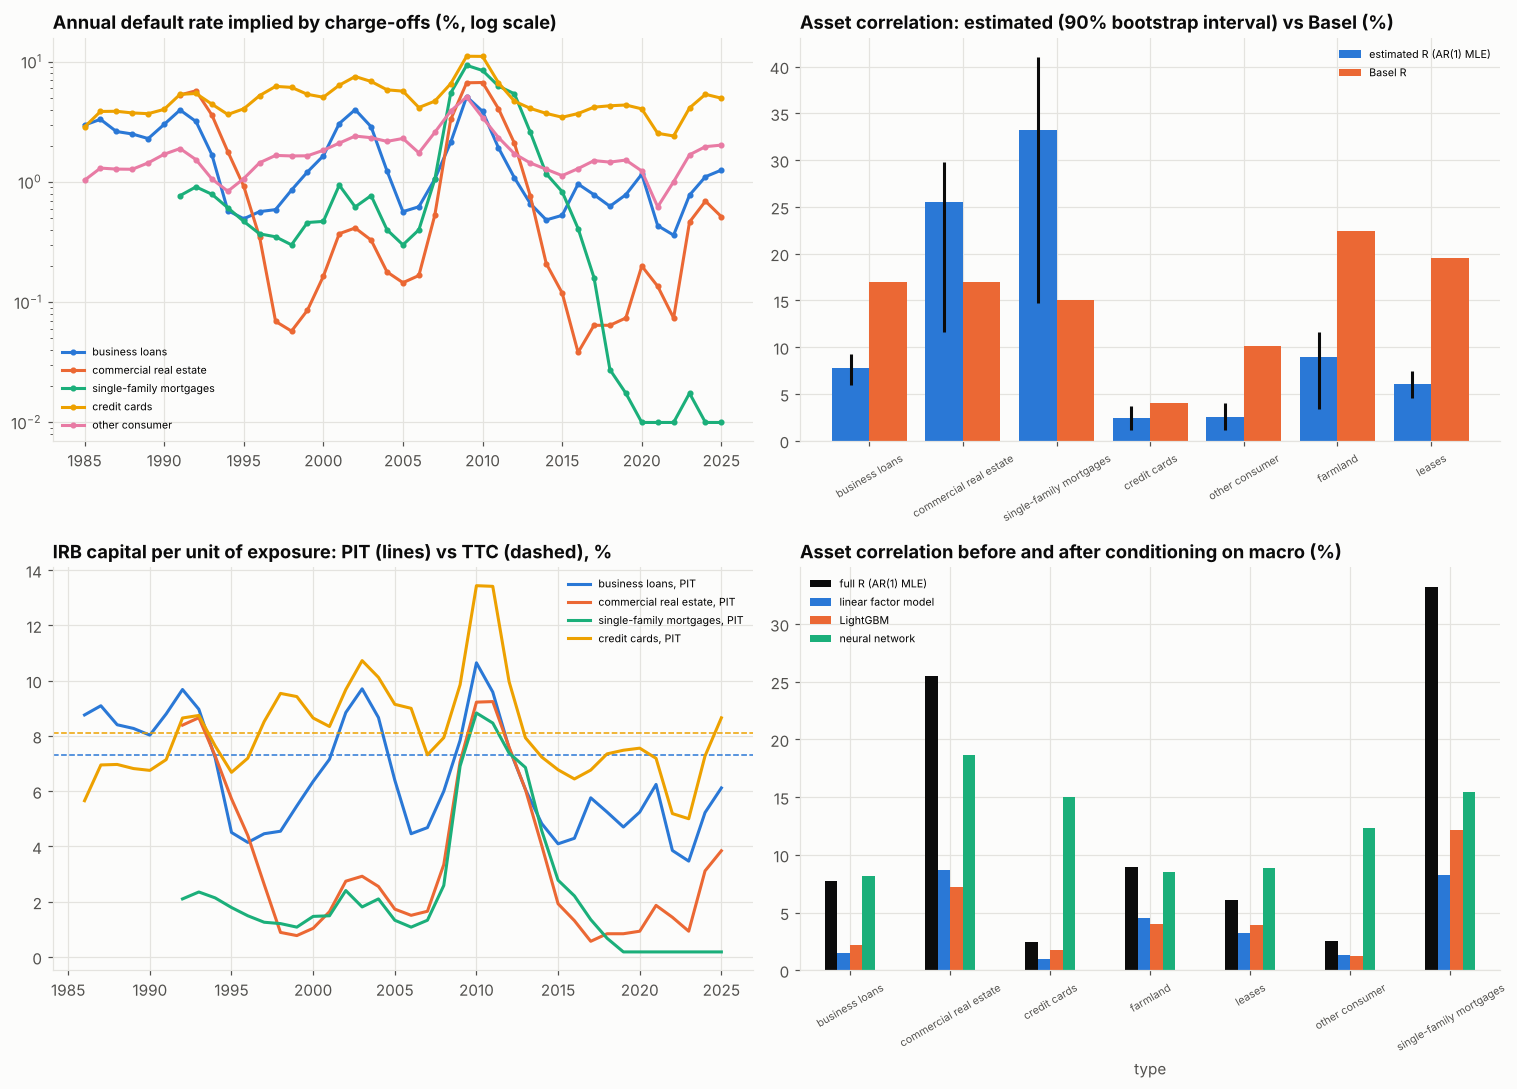

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for c, col in zip(
    [
        "business loans",
        "commercial real estate",
        "single-family mortgages",
        "credit cards",
        "other consumer",
    ],
    PALETTE,
):
    a.plot(DRA.index, DRA[c] * 100, marker="o", ms=3, color=col, label=c)
a.set_yscale("log")
a.set_title("Annual default rate implied by charge-offs (%, log scale)")
a.legend(fontsize=7)
a = ax[0, 1]
o = CORR.drop("all loans")
xpos = np.arange(len(o))
a.bar(
    xpos - 0.2,
    o["R, AR(1) MLE"].astype(float) * 100,
    0.4,
    color=PALETTE[0],
    label="estimated R (AR(1) MLE)",
)
a.errorbar(
    xpos - 0.2,
    o["R, AR(1) MLE"].astype(float) * 100,
    yerr=[
        (o["R, AR(1) MLE"] - o["R 90% interval low"])
        .astype(float)
        .clip(lower=0)
        * 100,
        (o["R 90% interval high"] - o["R, AR(1) MLE"])
        .astype(float)
        .clip(lower=0)
        * 100,
    ],
    fmt="none",
    color=INK,
)
a.bar(
    xpos + 0.2,
    o["Basel R"].astype(float) * 100,
    0.4,
    color=PALETTE[1],
    label="Basel R",
)
a.set_xticks(xpos)
a.set_xticklabels(o.index, rotation=30, fontsize=7)
a.set_title(
    "Asset correlation: estimated (90% bootstrap interval) vs Basel (%)"
)
a.legend(fontsize=7)
a = ax[1, 0]
for c, col in zip(
    [
        "business loans",
        "commercial real estate",
        "single-family mortgages",
        "credit cards",
    ],
    PALETTE,
):
    a.plot(CAPC.index, CAPC[(c, "PIT")] * 100, color=col, label=f"{c}, PIT")
    a.axhline(CAPC[(c, "TTC")].iloc[0] * 100, color=col, ls="--", lw=1)
a.set_title("IRB capital per unit of exposure: PIT (lines) vs TTC (dashed), %")
a.legend(fontsize=7)
a = ax[1, 1]
RESID.drop(columns="no change").drop(index="all loans", errors="ignore").mul(
    100
).plot.bar(ax=a, color=[INK] + PALETTE[:3], rot=30)
a.set_title("Asset correlation before and after conditioning on macro (%)")
a.legend(fontsize=7)
a.tick_params(axis="x", labelsize=7)
fig.tight_layout()
save_fig(fig, "01_asset_correlation")
plt.show()

In [9]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Return period of the worst year observed (years, log)",
        "Sensitivity of R to the LGD assumption (%)",
        "Out-of-time error of next-year default forecasts (RMSE, probit)",
        "Business loans: realised vs forecast probit default rate",
    ),
)
dash.add_trace(
    go.Bar(
        x=COVER.index,
        y=COVER["return period of worst year, Basel R (years)"],
        name="Basel R",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=COVER.index,
        y=COVER["return period, estimated R (years)"],
        name="estimated R",
    ),
    1,
    1,
)
for col in SENS.columns:
    dash.add_trace(
        go.Bar(x=SENS.index, y=SENS[col] * 100, name=str(col)), 1, 2
    )
for m in MODELS:
    dash.add_trace(
        go.Bar(x=list(ACC.columns), y=ACC.loc[m].values, name=m), 2, 1
    )
b = PRED[PRED["type"] == "business loans"]
dash.add_trace(
    go.Scatter(x=b.index, y=b["target"], name="realised", line_color=INK), 2, 2
)
for m in MODELS[1:]:
    dash.add_trace(go.Scatter(x=b.index, y=b[m], name=m), 2, 2)
dash.update_yaxes(type="log", row=1, col=1)
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Asset correlation from U.S. bank charge-offs: Vasicek vs Basel, and"
        " macro default models"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**Forty years of default rates.** Dividing charge-off rates by an LGD for each loan type gives long-run annual default rates of 1–2% for most books and 5% for credit cards. Every series peaked in 2009–2010:
- **Business loans:** 1.7% average, 5.1% in 2009.
- **Commercial real estate:** 1.3% average, 6.7% in 2010.
- **Single-family mortgages:** 1.4% average, 9.3% in 2009.
- **Credit cards:** 5.0% average, 11.1% in 2009.

Default rates are very persistent: the AR(1) coefficient of the systematic factor is 0.64–0.95, so bad years come in runs of three or four.

**Estimated correlations differ from Basel's, in both directions.**

| Loan type | Long-run PD | Estimated R (AR(1) MLE) | 90% bootstrap interval | Basel R | Estimate / Basel |
|---|---|---|---|---|---|
| Business loans | 1.8% | 7.7% | 5.9–9.3% | 17.0% | 0.46 |
| Commercial real estate | 1.8% | 25.5% | 11.6–29.8% | 17.0% | 1.51 |
| Single-family mortgages | 1.0% | 33.3% | 14.8–41.0% | 15.0% | 2.22 |
| Credit cards | 4.9% | 2.4% | 1.2–3.7% | 4.0% | 0.61 |
| Other consumer | 1.7% | 2.5% | 1.1–4.1% | 10.1% | 0.25 |
| Farmland | 0.3% | 8.9% | 3.4–11.6% | 22.4% | 0.40 |
| Leases | 0.9% | 6.1% | 4.6–7.5% | 19.5% | 0.31 |

- **Below Basel:** for business loans, consumer loans, cards, leases and farmland the estimates are well below Basel's R. These are diversified national portfolios: they behave like an average of many sectors and regions, while Basel's R must hold for a single bank's concentrated book.
- **Above Basel:** commercial real estate and mortgages are well above it. Their losses are dominated by one common factor, property prices, which fell everywhere at once in 2007–2011.

**Mortgages: correlated defaults or correlated losses?** Measured by delinquency rates, which do not depend on losses, the mortgage correlation is only 6.2%; measured by charge-offs, it is 33%. The difference is the link between defaults and loss severity. When house prices fall, more borrowers default and each default loses more, so charge-offs swing far more than defaults. Basel's formula assumes a fixed LGD (with a separate downturn LGD), so a 15% R for mortgages is consistent with the default data. The tail of mortgage losses is in LGD, not in R. For CRE the two proxies give 25.5% and 16.5%, again higher with losses. For business loans and cards they agree (7.7% and 8.0%; 2.4% and 2.2%). Lowering or raising the assumed LGD by 15 points moves the estimates by a few points but not their ranking.

**Would Basel capital have covered the worst year?** At each book's long-run PD:

| Loan type | Worst year (default rate) | 99.9% DR with Basel R | Return period of the worst year, Basel R | With estimated R |
|---|---|---|---|---|
| Business loans | 2009 (5.1%) | 18.0% | 15 years | 37 years |
| Commercial real estate | 2010 (6.7%) | 18.1% | 28 years | 19 years |
| Single-family mortgages | 2009 (9.3%) | 10.8% | 525 years | 69 years |
| Credit cards | 2009 (11.1%) | 14.4% | 96 years | 544 years |

Basel's 99.9% default rate exceeded the worst year for every book. For business loans, CRE, other consumer loans, farmland and leases, 2009–2010 was a 1-in-14-to-28-year event under Basel's R. For mortgages, Basel's R makes 2009 a 1-in-500-year event, close to the 1-in-1,000 capital standard, while the data's own correlation makes it a 1-in-70-year event: on a loss basis, the Basel mortgage calibration left little room.

**Point-in-time capital is strongly procyclical.** With last year's default rate as the PD and Basel's R:
- **Business loans:** capital per unit of exposure fell from 6.4% in 2005 to 4.5% in 2006, then rose to 10.7% in 2010; the through-the-cycle level is 7.3%.
- **Mortgages:** capital was 1.1–1.3% in 2005–2007 and 8.8% in 2010. With the near-zero charge-offs of 2021–2025 it fell to 0.2%, below even the 2006 level.

A point-in-time bank would have entered the crisis with the least capital in the cycle.

**The macro economy explains most of the common factor.** Out of time from 2000, forecasting the next four quarters' probit default rate:
- **Accuracy:** the linear factor model (RMSE 0.198) and LightGBM (0.212) are about as accurate as assuming no change (0.200). All three were worse in the turns of 2008–2010 and 2020–2021, and no model beat no-change in those periods. The neural network, even regularised, was the least accurate (0.391), with errors above 0.8 in the crisis.
- **Residual correlation:** what the macro models leave unexplained is much smaller than the full R. For business loans it is 1.5–2.2% (against 7.7%), for cards about 1–2% (against 2.4%), for CRE 7–9% (against 25.5%) and for mortgages 8–12% (against 33%). A PD model that tracks the cycle needs a much lower correlation for its capital to equal that of a through-the-cycle model. If it keeps Basel's R, it counts the cycle twice: once in the PD and again in the correlation.

**What this means for credit-risk modelling and validation.**
- **Calibrating R:** Basel's correlations are conservative for diversified corporate and consumer books but not for real estate. Real-estate risk comes as much from LGD as from defaults, so downturn LGD deserves as much validation effort as PD.
- **Data:** forty years contain essentially one severe credit cycle. Confidence intervals for R are wide (CRE: 12–30%), and estimates from a single cycle should be treated as a lower bound for books that did not suffer in 2009.
- **Model choice:** machine learning adds little to a linear macro model of aggregate default rates; with about forty years of national data, the gain is in using cross-sectional data (banks, regions, sectors), not in a more flexible function.
- **PIT models:** they should be paired with a cycle adjustment or a lower, residual correlation, or capital will swing with the economy.

**Limitations.**
- **Default proxy:** charge-off rates divided by a fixed LGD mix default and loss severity, and are distorted when charge-offs are near zero. Recent mortgage rates are floored at one basis point. Delinquency rates are an alternative proxy for only five books and measure stock rather than flow.
- **Aggregation:** national aggregates of all commercial banks are more diversified than any one bank's portfolio, so they understate the correlation a single bank faces, and they mix loan types within each category.
- **Model:** the asymptotic single-factor model ignores granularity, sector concentration and contagion. The AR(1) factor is the simplest dynamic; the estimates rest on 35–41 annual observations.
- **Macro models:** they use national variables and quarterly data with overlapping four-quarter targets; their residuals are evaluated on non-overlapping year-end windows only.

In [10]:
SUMMARY.to_csv(OUT_DIR / "default_rates_summary.csv")
CORR.to_csv(OUT_DIR / "asset_correlation_estimates.csv")
COVER.to_csv(OUT_DIR / "worst_year_coverage.csv")
SENS.to_csv(OUT_DIR / "lgd_sensitivity.csv")
CAPC.to_csv(OUT_DIR / "capital_through_the_cycle.csv")
ACC.to_csv(OUT_DIR / "macro_default_model_accuracy.csv")
RESID.to_csv(OUT_DIR / "residual_correlation.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_asset_correlation.png, asset_correlation_estimates.csv, capital_through_the_cycle.csv, dashboard.html, dashboard.png, default_rates_summary.csv, lgd_sensitivity.csv, macro_default_model_accuracy.csv, residual_correlation.csv, worst_year_coverage.csv


## References

### Finance and regulation

- Vasicek, O. (2002). The distribution of loan portfolio value. *Risk, 15*(12), 160–162.
- Gordy, M. B. (2003). A risk-factor model foundation for ratings-based bank capital rules. *Journal of Financial Intermediation, 12*(3), 199–232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Lopez, J. A. (2004). The empirical relationship between average asset correlation, firm probability of default, and asset size. *Journal of Financial Intermediation, 13*(2), 265–283. https://doi.org/10.1016/S1042-9573(03)00045-7
- Basel Committee on Banking Supervision. (2005). *An explanatory note on the Basel II IRB risk weight functions*. Bank for International Settlements. https://www.bis.org/bcbs/irbriskweight.htm
- Repullo, R., Saurina, J., & Trucharte, C. (2010). Mitigating the pro-cyclicality of Basel II. *Economic Policy, 25*(64), 659–702. https://doi.org/10.1111/j.1468-0327.2010.00252.x
- Board of Governors of the Federal Reserve System. (2026). *Charge-off and delinquency rates on loans and leases at commercial banks* [Data set]. Federal Reserve Bank of St. Louis (FRED). https://fred.stlouisfed.org/

### Machine learning and statistics

- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241. https://doi.org/10.1214/aos/1176347265
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html